<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Trees 2: XGBoost

In [1]:
import numpy as np
from sklearn import metrics, inspection, datasets
from matplotlib import pyplot as plt

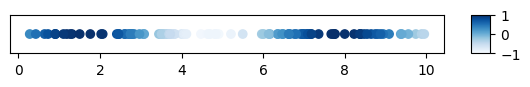

In [2]:
x = np.random.uniform(0, 10, size=(100,))
y = np.sin(x) + np.random.rand(100) * 0.1

fig, ax = plt.subplots(figsize=(7, 0.5))
scatter = ax.scatter(x, np.zeros_like(x), c=y, cmap="Blues", vmin=-1, vmax=1)
ax.set_yticks([])
fig.colorbar(scatter, ax=ax, aspect=2)
plt.show()

In [3]:
# create an array of zeros with same shape as x
preds_y0 = np.full(x.shape, 0)

In [4]:
def loss(y_true, y_pred):
    return (y_true - y_pred) ** 2

mse_loss = loss(y, preds_y0)

In [5]:
def grad_loss(y_true, y_pred):
    return 2 * (y_true - y_pred)

# The derivative is just 2 for all x values
# so we create an array of 2s with same shape as x
def grad_grad_loss(y_true, y_pred):
    return np.full(y_pred.shape, 2)

In [6]:
# XGBoost defaults for regularization params
lambd = 1
gamma = 0

# this computes the score, as introduced in the reading. Skim this.
def leaf_score(leaf_true_ys, leaf_pred_ys):
    numerator = np.sum(grad_loss(leaf_true_ys, leaf_pred_ys)**2)
    denominator = np.sum(grad_grad_loss(leaf_true_ys, leaf_pred_ys)**2)
    return numerator / (denominator + lambd)


# You only need to use this function directly to solve this question:
def gain(x, y, preds, threshold):
    # The threshold should be a real valued number
    left_mask = x <= threshold
    right_mask = x >= threshold

    left_child = leaf_score(y[left_mask], preds[left_mask])
    right_child = leaf_score(y[right_mask], preds[right_mask])
    parent = leaf_score(y, preds)
    gain = 0.5 * (left_child + right_child - parent) - gamma
    return gain

In [7]:
# Question

# Here's a sample way to use this function
print(gain(x, y, preds_y0, threshold=5))

thresholds = np.unique(x)
gains = [gain(x, y, preds_y0, i) for i in thresholds]

best_threshold = thresholds[np.argmax(gains)]
print(f"Threshold value = {best_threshold} \nHighest gain = {max(gains)}")

0.22683473842213778
Threshold value = 2.0650100037869024 
Highest gain = 0.3462992580260543


In [8]:
# Q3
def best_split(xs, ys, ps):
    best_t, best_g = None, -np.inf
    for t in np.unique(xs):
        g = gain(xs, ys, ps, t)
        if g > best_g:
            best_t, best_g = t, g
    return best_t

In [9]:
# first split
t1 = best_split(x, y, preds_y0)

# splitting the data at t1, then searching each half separately
x_left, y_left, p_left = [], [], []
x_right, y_right, p_right = [], [], []

for i in range(len(x)):
    if x[i] <= t1:
        x_left.append(x[i])
        y_left.append(y[i])
        p_left.append(preds_y0[i])
    else:
        x_right.append(x[i])
        y_right.append(y[i])
        p_right.append(preds_y0[i])

x_left, y_left, p_left = np.array(x_left), np.array(y_left), np.array(p_left)
x_right, y_right, p_right = np.array(x_right), np.array(y_right), np.array(p_right)

t_left = best_split(x_left, y_left, p_left)
t_right = best_split(x_right, y_right, p_right)

print("first split:", t1)
print("left split:", t_left)
print("right split:", t_right)

first split: 2.0650100037869024
left split: 1.5017359139281672
right split: 7.3609529994549705
